# Elon Musk Tweet EDA (Focused)

This notebook is intentionally trimmed to **only the high-value plots** for trading-relevant behavior on the full historical window we currently have.

**Scope used in analysis:** 2009-01-01 UTC to now (dataset coverage may start later).

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer as SIA

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["legend.frameon"] = False

nltk.download("vader_lexicon", quiet=True)

True

In [2]:
# Resolve project root robustly (works from JupyterHub/local no matter cwd)
_CWD = Path(os.getcwd()).resolve()
_candidates = [
    Path('/Users/andreiojoc/polybot'),
    _CWD,
    _CWD.parent,
    *_CWD.parents,
]

_ROOT = None
for cand in _candidates:
    if (cand / 'data').is_dir():
        _ROOT = cand
        break

if _ROOT is None:
    raise RuntimeError(
        'Could not locate project root containing data/. '
        f'cwd={_CWD}. Please open this notebook from /Users/andreiojoc/polybot.'
    )

analysis_start = pd.Timestamp('2009-01-01T00:00:00Z')
analysis_end = pd.Timestamp.now(tz='UTC')

parquet_path = _ROOT / 'data' / 'tweets_all.parquet'
csv_path = _ROOT / 'data' / 'tweets_all.csv'

# Load merged dataset with kernel-friendly fallback.
# Some JupyterHub kernels do not have pyarrow/fastparquet.
if parquet_path.exists():
    try:
        df = pd.read_parquet(parquet_path)
        print(f'Loaded parquet: {parquet_path}')
    except Exception as exc:
        if csv_path.exists():
            df = pd.read_csv(csv_path, low_memory=False)
            print(f'Parquet unavailable ({exc}); loaded CSV fallback: {csv_path}')
        else:
            raise RuntimeError(
                f'Parquet read failed ({exc}) and CSV fallback missing at {csv_path}. '
                'Create CSV once from a parquet-capable env: data/tweets_all.parquet -> data/tweets_all.csv.'
            )
elif csv_path.exists():
    df = pd.read_csv(csv_path, low_memory=False)
    print(f'Loaded CSV: {csv_path}')
else:
    raise FileNotFoundError(
        f'Missing both {parquet_path} and {csv_path}. Build data with: python -m ingestion.collect --refresh'
    )

df = df.copy()
df['text'] = df['text'].fillna('').astype(str)
df['dt'] = pd.to_datetime(df['date'], utc=True, errors='coerce')
df = df.dropna(subset=['dt']).sort_values('dt')
df = df[(df['dt'] >= analysis_start) & (df['dt'] <= analysis_end)].copy()

# Temporal columns
df['year'] = df['dt'].dt.year
df['month'] = df['dt'].dt.month
df['month_start'] = df['dt'].dt.to_period('M').dt.to_timestamp().dt.tz_localize('UTC')
df['hour_utc'] = df['dt'].dt.hour
df['weekday'] = df['dt'].dt.dayofweek
weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df['weekday_name'] = df['weekday'].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df['sentiment'] = df['text'].apply(lambda t: sia.polarity_scores(t)['compound'])
df['sentiment_label'] = pd.cut(
    df['sentiment'],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=['negative', 'neutral', 'positive'],
)

earliest, latest = df['dt'].min(), df['dt'].max()
print(f'Project root: {_ROOT}')
print(f'Rows: {len(df):,}')
print(f'Coverage in file: {earliest} -> {latest}')
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f'Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}.'
    )


Loaded parquet: /Users/andreiojoc/polybot/data/tweets_all.parquet


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3772358482.py:60: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month_start'] = df['dt'].dt.to_period('M').dt.to_timestamp().dt.tz_localize('UTC')


Project root: /Users/andreiojoc/polybot
Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


In [3]:
# Resolve project root robustly (works from repo root or notebooks context)
_CWD = Path(os.getcwd()).resolve()
if (_CWD / "ingestion").is_dir():
    _ROOT = _CWD
elif (_CWD.parent / "ingestion").is_dir():
    _ROOT = _CWD.parent
else:
    _ROOT = _CWD

if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from ingestion.merger import load_merged

analysis_start = pd.Timestamp("2009-01-01T00:00:00Z")
analysis_end = pd.Timestamp.now(tz="UTC")

df = load_merged(
    cache_path=_ROOT / "data" / "tweets_all.parquet",
    sse_path=_ROOT / "tweet_signal_events.jsonl",
    x_full_archive_path=_ROOT / "data" / "x_api_full_archive_raw.jsonl",
    twscrape_path=_ROOT / "data" / "twscrape_raw.jsonl",
    kaggle_dir=_ROOT / "data" / "kaggle",
)

df = df.copy()
df["text"] = df["text"].fillna("").astype(str)
df["dt"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
df = df.dropna(subset=["dt"]).sort_values("dt")
df = df[(df["dt"] >= analysis_start) & (df["dt"] <= analysis_end)].copy()

# Temporal columns
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")
df["hour_utc"] = df["dt"].dt.hour
df["weekday"] = df["dt"].dt.dayofweek
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = df["weekday"].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df["sentiment"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment_label"] = pd.cut(
    df["sentiment"],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=["negative", "neutral", "positive"],
)

earliest, latest = df["dt"].min(), df["dt"].max()
print(f"Rows: {len(df):,}")
print(f"Coverage in file: {earliest} -> {latest}")
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f"Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}."
    )

Loaded 69,476 tweets from cache | 2010-06-04 → 2026-05-01


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3626712124.py:35: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")


Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


In [4]:
# Resolve project root robustly (works from repo root or notebooks context)
_CWD = Path(os.getcwd()).resolve()
if (_CWD / "ingestion").is_dir():
    _ROOT = _CWD
elif (_CWD.parent / "ingestion").is_dir():
    _ROOT = _CWD.parent
else:
    _ROOT = _CWD

if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from ingestion.merger import load_merged

analysis_start = pd.Timestamp("2009-01-01T00:00:00Z")
analysis_end = pd.Timestamp.now(tz="UTC")

df = load_merged(
    cache_path=_ROOT / "data" / "tweets_all.parquet",
    sse_path=_ROOT / "tweet_signal_events.jsonl",
    x_full_archive_path=_ROOT / "data" / "x_api_full_archive_raw.jsonl",
    twscrape_path=_ROOT / "data" / "twscrape_raw.jsonl",
    kaggle_dir=_ROOT / "data" / "kaggle",
)

df = df.copy()
df["text"] = df["text"].fillna("").astype(str)
df["dt"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
df = df.dropna(subset=["dt"]).sort_values("dt")
df = df[(df["dt"] >= analysis_start) & (df["dt"] <= analysis_end)].copy()

# Temporal columns
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")
df["hour_utc"] = df["dt"].dt.hour
df["weekday"] = df["dt"].dt.dayofweek
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = df["weekday"].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df["sentiment"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment_label"] = pd.cut(
    df["sentiment"],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=["negative", "neutral", "positive"],
)

earliest, latest = df["dt"].min(), df["dt"].max()
print(f"Rows: {len(df):,}")
print(f"Coverage in file: {earliest} -> {latest}")
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f"Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}."
    )

Loaded 69,476 tweets from cache | 2010-06-04 → 2026-05-01


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3626712124.py:35: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")


Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


In [5]:
# Resolve project root robustly (works from repo root or notebooks context)
_CWD = Path(os.getcwd()).resolve()
if (_CWD / "ingestion").is_dir():
    _ROOT = _CWD
elif (_CWD.parent / "ingestion").is_dir():
    _ROOT = _CWD.parent
else:
    _ROOT = _CWD

if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from ingestion.merger import load_merged

analysis_start = pd.Timestamp("2009-01-01T00:00:00Z")
analysis_end = pd.Timestamp.now(tz="UTC")

df = load_merged(
    cache_path=_ROOT / "data" / "tweets_all.parquet",
    sse_path=_ROOT / "tweet_signal_events.jsonl",
    x_full_archive_path=_ROOT / "data" / "x_api_full_archive_raw.jsonl",
    twscrape_path=_ROOT / "data" / "twscrape_raw.jsonl",
    kaggle_dir=_ROOT / "data" / "kaggle",
)

df = df.copy()
df["text"] = df["text"].fillna("").astype(str)
df["dt"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
df = df.dropna(subset=["dt"]).sort_values("dt")
df = df[(df["dt"] >= analysis_start) & (df["dt"] <= analysis_end)].copy()

# Temporal columns
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")
df["hour_utc"] = df["dt"].dt.hour
df["weekday"] = df["dt"].dt.dayofweek
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = df["weekday"].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df["sentiment"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment_label"] = pd.cut(
    df["sentiment"],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=["negative", "neutral", "positive"],
)

earliest, latest = df["dt"].min(), df["dt"].max()
print(f"Rows: {len(df):,}")
print(f"Coverage in file: {earliest} -> {latest}")
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f"Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}."
    )

Loaded 69,476 tweets from cache | 2010-06-04 → 2026-05-01


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3626712124.py:35: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")


Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


In [6]:
# Resolve project root robustly (works from repo root or notebooks context)
_CWD = Path(os.getcwd()).resolve()
if (_CWD / "ingestion").is_dir():
    _ROOT = _CWD
elif (_CWD.parent / "ingestion").is_dir():
    _ROOT = _CWD.parent
else:
    _ROOT = _CWD

if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from ingestion.merger import load_merged

analysis_start = pd.Timestamp("2009-01-01T00:00:00Z")
analysis_end = pd.Timestamp.now(tz="UTC")

df = load_merged(
    cache_path=_ROOT / "data" / "tweets_all.parquet",
    sse_path=_ROOT / "tweet_signal_events.jsonl",
    x_full_archive_path=_ROOT / "data" / "x_api_full_archive_raw.jsonl",
    twscrape_path=_ROOT / "data" / "twscrape_raw.jsonl",
    kaggle_dir=_ROOT / "data" / "kaggle",
)

df = df.copy()
df["text"] = df["text"].fillna("").astype(str)
df["dt"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
df = df.dropna(subset=["dt"]).sort_values("dt")
df = df[(df["dt"] >= analysis_start) & (df["dt"] <= analysis_end)].copy()

# Temporal columns
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")
df["hour_utc"] = df["dt"].dt.hour
df["weekday"] = df["dt"].dt.dayofweek
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = df["weekday"].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df["sentiment"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment_label"] = pd.cut(
    df["sentiment"],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=["negative", "neutral", "positive"],
)

earliest, latest = df["dt"].min(), df["dt"].max()
print(f"Rows: {len(df):,}")
print(f"Coverage in file: {earliest} -> {latest}")
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f"Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}."
    )

Loaded 69,476 tweets from cache | 2010-06-04 → 2026-05-01


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3626712124.py:35: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")


Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


In [7]:
# Resolve project root robustly (works from repo root or notebooks context)
_CWD = Path(os.getcwd()).resolve()
if (_CWD / "ingestion").is_dir():
    _ROOT = _CWD
elif (_CWD.parent / "ingestion").is_dir():
    _ROOT = _CWD.parent
else:
    _ROOT = _CWD

if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from ingestion.merger import load_merged

analysis_start = pd.Timestamp("2009-01-01T00:00:00Z")
analysis_end = pd.Timestamp.now(tz="UTC")

df = load_merged(
    cache_path=_ROOT / "data" / "tweets_all.parquet",
    sse_path=_ROOT / "tweet_signal_events.jsonl",
    x_full_archive_path=_ROOT / "data" / "x_api_full_archive_raw.jsonl",
    twscrape_path=_ROOT / "data" / "twscrape_raw.jsonl",
    kaggle_dir=_ROOT / "data" / "kaggle",
)

df = df.copy()
df["text"] = df["text"].fillna("").astype(str)
df["dt"] = pd.to_datetime(df["date"], utc=True, errors="coerce")
df = df.dropna(subset=["dt"]).sort_values("dt")
df = df[(df["dt"] >= analysis_start) & (df["dt"] <= analysis_end)].copy()

# Temporal columns
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")
df["hour_utc"] = df["dt"].dt.hour
df["weekday"] = df["dt"].dt.dayofweek
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["weekday_name"] = df["weekday"].map(dict(enumerate(weekday_names)))

# Sentiment (VADER)
sia = SIA()
df["sentiment"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["sentiment_label"] = pd.cut(
    df["sentiment"],
    bins=[-1.0, -0.05, 0.05, 1.0],
    labels=["negative", "neutral", "positive"],
)

earliest, latest = df["dt"].min(), df["dt"].max()
print(f"Rows: {len(df):,}")
print(f"Coverage in file: {earliest} -> {latest}")
if pd.notna(earliest) and earliest.year > 2009:
    print(
        f"Note: the requested window starts at 2009, but current earliest tweet is {earliest.date()}."
    )

Loaded 69,476 tweets from cache | 2010-06-04 → 2026-05-01


/var/folders/60/mg79fl3d6szdw1dbrhh1w8w00000gn/T/ipykernel_90277/3626712124.py:35: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month_start"] = df["dt"].dt.to_period("M").dt.to_timestamp().dt.tz_localize("UTC")


Rows: 69,476
Coverage in file: 2010-06-04 18:31:57+00:00 -> 2026-05-01 23:24:43+00:00
Note: the requested window starts at 2009, but current earliest tweet is 2010-06-04.


## 1) Coverage & Missing-Month Gaps

This verifies what we can and cannot trust in time-series model training.

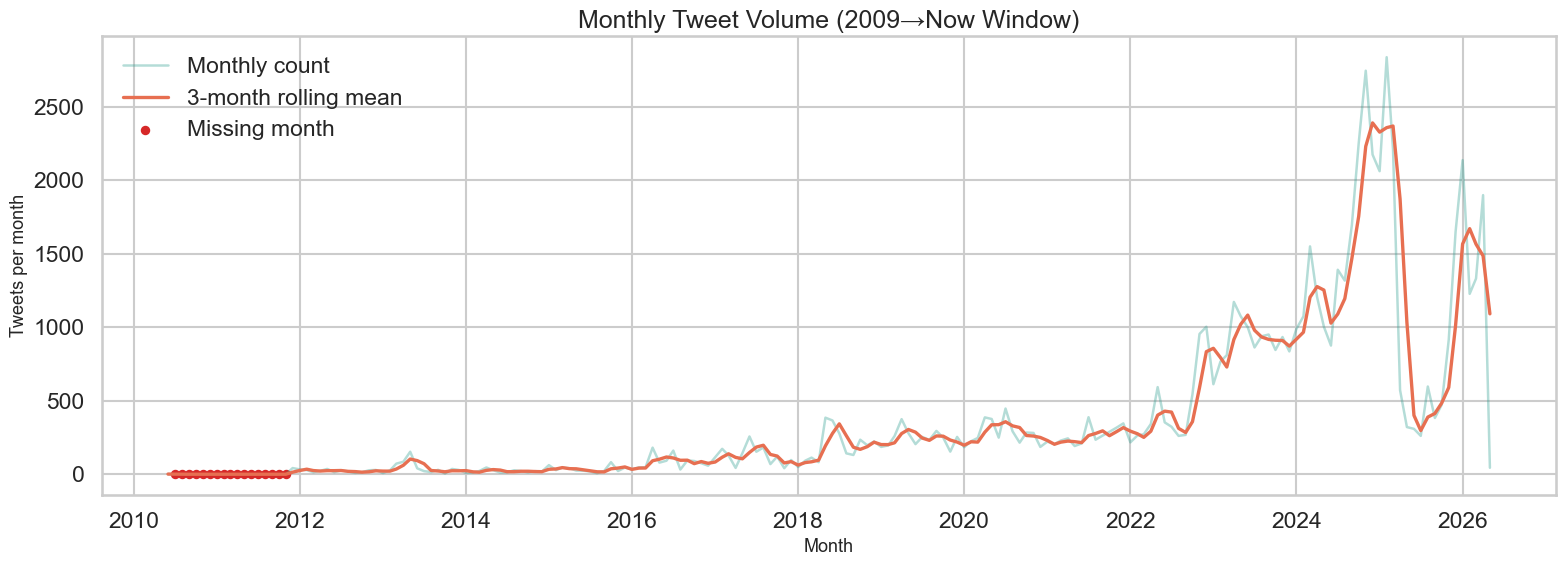

Missing months in observed coverage: 17
First missing months: 2010-07, 2010-08, 2010-09, 2010-10, 2010-11, 2010-12, 2011-01, 2011-02, 2011-03, 2011-04, 2011-05, 2011-06


In [8]:
monthly = (
    df.set_index("dt")
    .resample("MS")
    .size()
    .rename("tweet_count")
)
full_months = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS", tz="UTC")
monthly = monthly.reindex(full_months, fill_value=0)
monthly_roll = monthly.rolling(3, min_periods=1).mean()
missing_months = monthly[monthly == 0]

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(monthly.index, monthly.values, color="#2a9d8f", alpha=0.35, lw=1.8, label="Monthly count")
ax.plot(monthly_roll.index, monthly_roll.values, color="#e76f51", lw=2.4, label="3-month rolling mean")
if len(missing_months):
    ax.scatter(missing_months.index, np.zeros(len(missing_months)), color="#d62828", s=28, label="Missing month")

ax.set_title("Monthly Tweet Volume (2009→Now Window)")
ax.set_ylabel("Tweets per month")
ax.set_xlabel("Month")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Missing months in observed coverage: {len(missing_months)}")
if len(missing_months):
    print("First missing months:", ", ".join([d.strftime("%Y-%m") for d in missing_months.index[:12]]))

## 2) Activity Heatmap (Day of Week × UTC Hour)

Useful for timing entries and estimating when burst probability is naturally high.

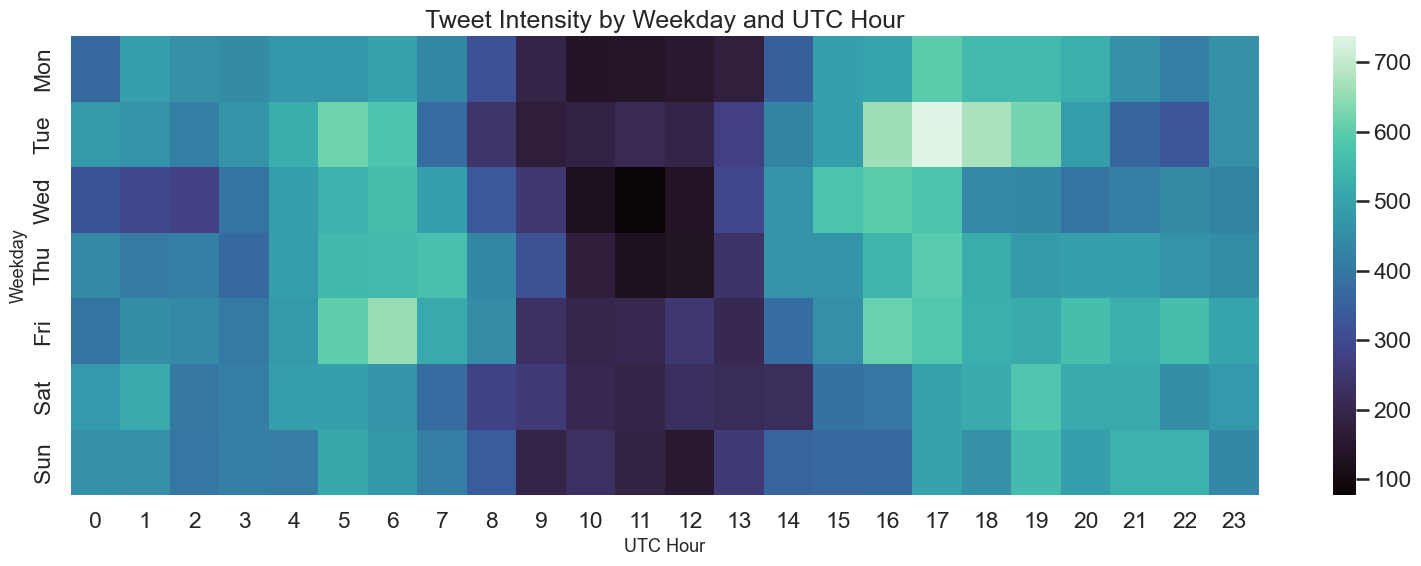

In [9]:
heat = (
    df.groupby(["weekday_name", "hour_utc"])['tweet_id']
    .count()
    .unstack(fill_value=0)
    .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
)

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(heat, cmap="mako", ax=ax)
ax.set_title("Tweet Intensity by Weekday and UTC Hour")
ax.set_xlabel("UTC Hour")
ax.set_ylabel("Weekday")
plt.tight_layout()
plt.show()

## 3) Sleep-Cycle Proxy (Silence Probability by UTC Hour)

Higher value means Elon is more likely to be inactive in that hour.

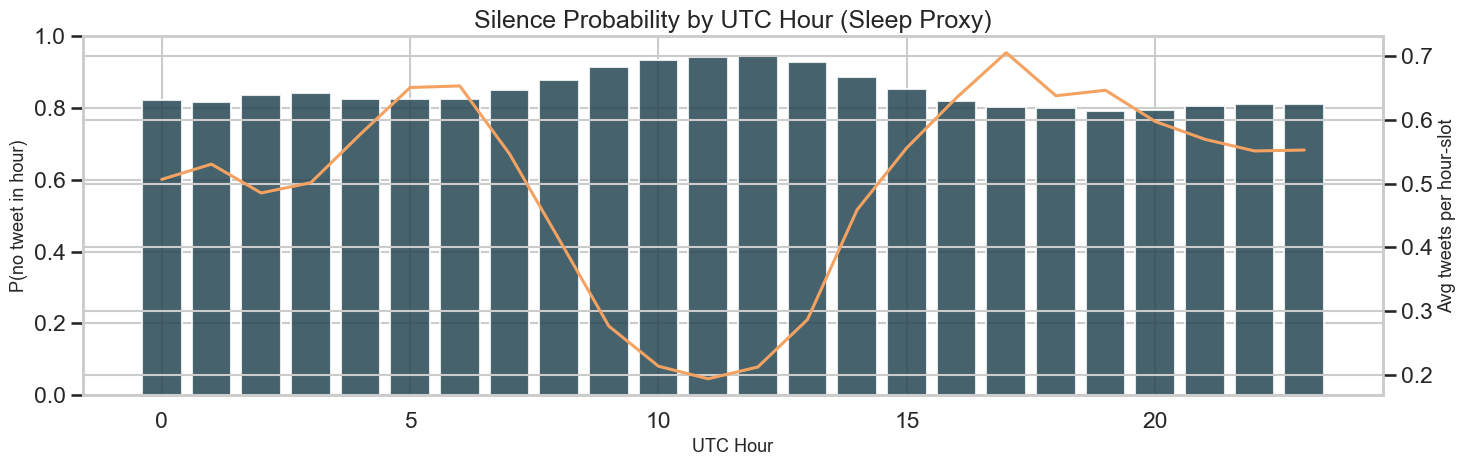

In [10]:
slot_counts = (
    df.groupby([df["dt"].dt.date.rename("date_only"), "hour_utc"])['tweet_id']
    .count()
    .reset_index(name="count")
)
all_dates = pd.date_range(df["dt"].min().date(), df["dt"].max().date(), freq="D")
grid = pd.MultiIndex.from_product([all_dates.date, range(24)], names=["date_only", "hour_utc"]).to_frame(index=False)
slots = grid.merge(slot_counts, on=["date_only", "hour_utc"], how="left")
slots["count"] = slots["count"].fillna(0)

silence_prob = slots.groupby("hour_utc")["count"].apply(lambda s: (s == 0).mean())
activity_mean = slots.groupby("hour_utc")["count"].mean()

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.bar(silence_prob.index, silence_prob.values, color="#264653", alpha=0.85)
ax1.set_title("Silence Probability by UTC Hour (Sleep Proxy)")
ax1.set_xlabel("UTC Hour")
ax1.set_ylabel("P(no tweet in hour)")
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
ax2.plot(activity_mean.index, activity_mean.values, color="#f4a261", lw=2.2)
ax2.set_ylabel("Avg tweets per hour-slot")

plt.tight_layout()
plt.show()

## 4) Retweet Behavior Over Time

This is directly relevant for your self-excitation idea.

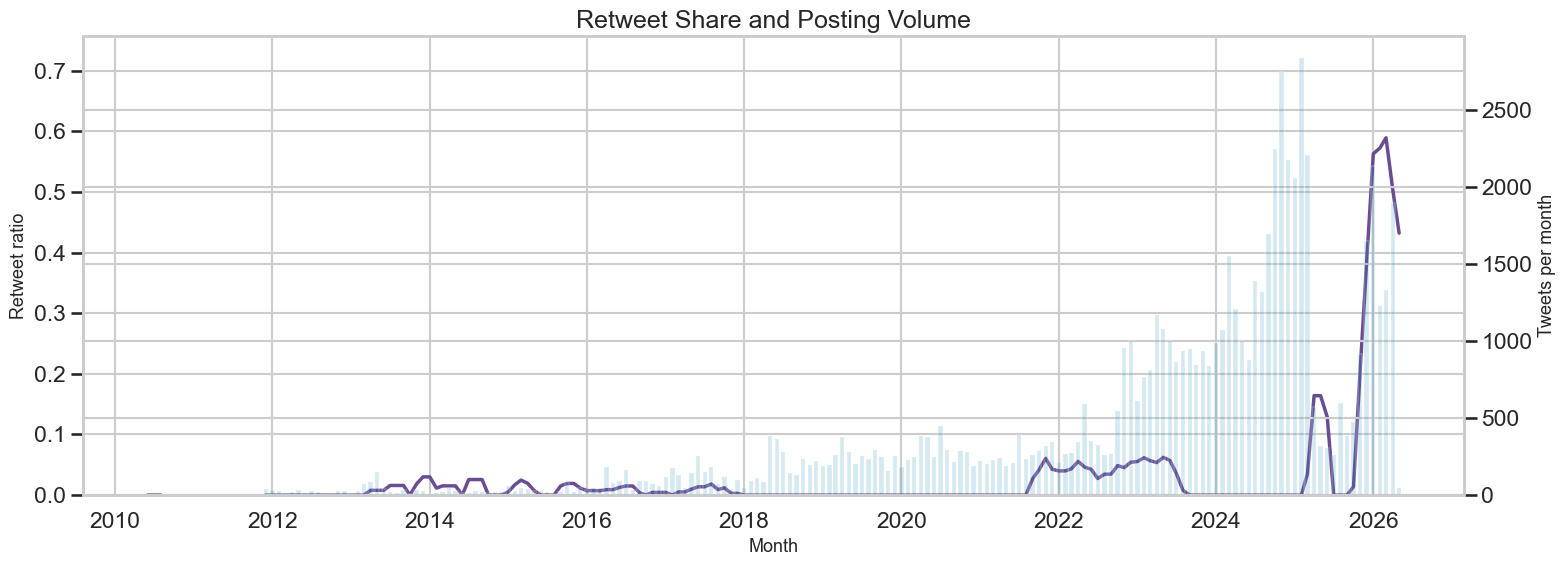

In [11]:
retweet_monthly = (
    df.set_index("dt")
    .resample("MS")
    .agg(tweet_count=("tweet_id", "count"), rt_ratio=("is_retweet", "mean"))
)
retweet_monthly["rt_ratio_roll"] = retweet_monthly["rt_ratio"].rolling(3, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(16, 6))
ax1.plot(
    retweet_monthly.index,
    retweet_monthly["rt_ratio_roll"],
    color="#6a4c93",
    lw=2.5,
    label="Retweet ratio (3M rolling)",
)
ax1.set_ylabel("Retweet ratio")
ax1.set_ylim(0, min(1.0, retweet_monthly["rt_ratio_roll"].max() * 1.25 + 0.02))
ax1.set_xlabel("Month")
ax1.set_title("Retweet Share and Posting Volume")

ax2 = ax1.twinx()
ax2.bar(retweet_monthly.index, retweet_monthly["tweet_count"], width=20, alpha=0.18, color="#118ab2")
ax2.set_ylabel("Tweets per month")

plt.tight_layout()
plt.show()

## 5) Does a Retweet Increase Near-Term Tweet Probability?

Compares probability that the **next** tweet arrives quickly after a retweet vs after an original tweet.

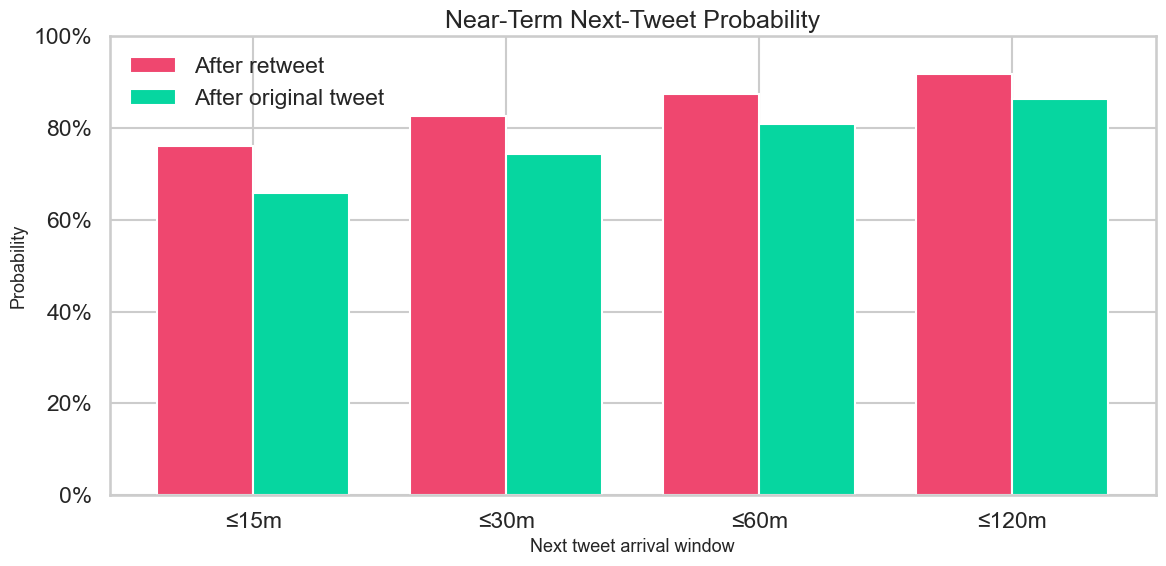

,window_min,after_retweet,after_original
0,15,0.761768,0.657928
1,30,0.826725,0.743816
2,60,0.873292,0.809656
3,120,0.918846,0.863143


In [12]:
seq = df[["dt", "is_retweet"]].sort_values("dt").reset_index(drop=True)
seq["next_gap_min"] = (seq["dt"].shift(-1) - seq["dt"]).dt.total_seconds() / 60
seq = seq.iloc[:-1].copy()

windows = [15, 30, 60, 120]
rows = []
for w in windows:
    after_rt = (seq.loc[seq["is_retweet"], "next_gap_min"] <= w).mean()
    after_orig = (seq.loc[~seq["is_retweet"], "next_gap_min"] <= w).mean()
    rows.append({
        "window_min": w,
        "after_retweet": after_rt,
        "after_original": after_orig,
    })

rt_effect = pd.DataFrame(rows)

x = np.arange(len(rt_effect))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width/2, rt_effect["after_retweet"], width=width, color="#ef476f", label="After retweet")
ax.bar(x + width/2, rt_effect["after_original"], width=width, color="#06d6a0", label="After original tweet")
ax.set_xticks(x)
ax.set_xticklabels([f"≤{w}m" for w in rt_effect["window_min"]])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Near-Term Next-Tweet Probability")
ax.set_ylabel("Probability")
ax.set_xlabel("Next tweet arrival window")
ax.legend()
plt.tight_layout()
plt.show()

rt_effect

## 6) Sentiment Snapshot (Distribution + Trend)

High-level signal features we can ingest into the model (sentiment level + drift).

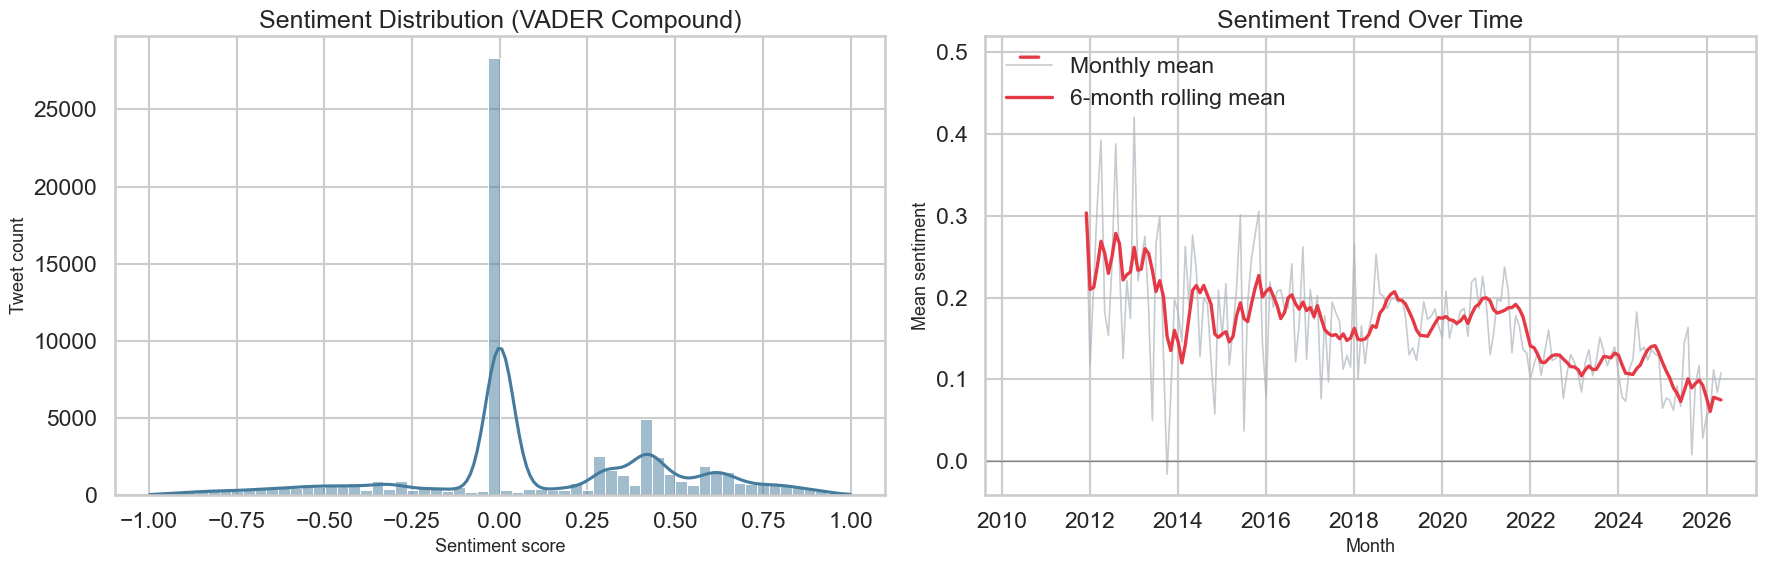

,pct
sentiment_label,
positive,41.57
neutral,41.41
negative,17.02


In [13]:
monthly_sent = (
    df.set_index("dt")
    .resample("MS")
    .agg(mean_sentiment=("sentiment", "mean"), tweet_count=("tweet_id", "count"))
)
monthly_sent["sentiment_roll_6m"] = monthly_sent["mean_sentiment"].rolling(6, min_periods=1).mean()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(df["sentiment"], bins=60, kde=True, color="#457b9d", ax=axes[0])
axes[0].set_title("Sentiment Distribution (VADER Compound)")
axes[0].set_xlabel("Sentiment score")
axes[0].set_ylabel("Tweet count")

axes[1].plot(monthly_sent.index, monthly_sent["mean_sentiment"], color="#adb5bd", lw=1.2, alpha=0.7, label="Monthly mean")
axes[1].plot(monthly_sent.index, monthly_sent["sentiment_roll_6m"], color="#e63946", lw=2.4, label="6-month rolling mean")
axes[1].axhline(0, color="black", lw=1, alpha=0.35)
axes[1].set_title("Sentiment Trend Over Time")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean sentiment")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

(df["sentiment_label"].value_counts(normalize=True).mul(100).round(2).rename("pct").to_frame())

## 7) Source Mix (Sanity Check)

Confirms which pipelines currently dominate the historical dataset.

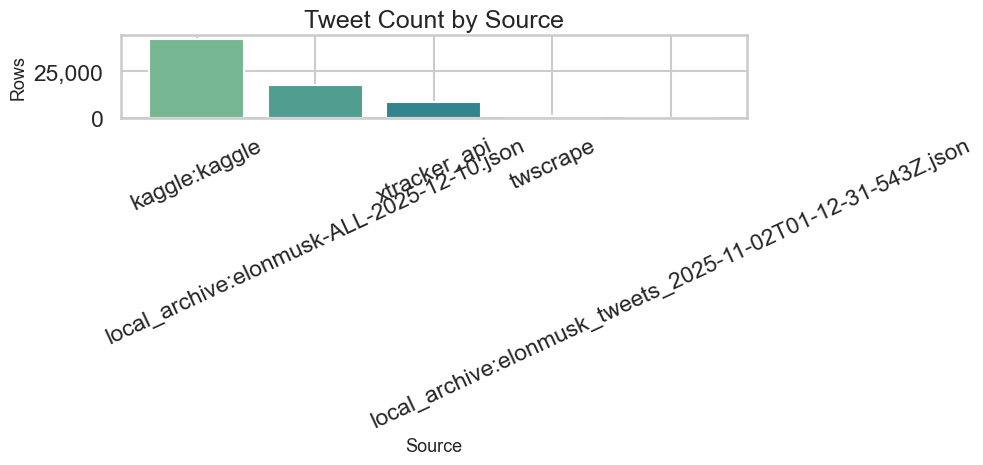

,rows
source,
kaggle:kaggle,42468
local_archive:elonmusk-ALL-2025-12-10.json,17734
xtracker_api,8388
twscrape,880
local_archive:elonmusk_tweets_2025-11-02T01-12-31-543Z.json,6


In [14]:
source_counts = df["source"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("crest", n_colors=len(source_counts))
ax.bar(source_counts.index, source_counts.values, color=colors)
ax.set_title("Tweet Count by Source")
ax.set_ylabel("Rows")
ax.set_xlabel("Source")
ax.tick_params(axis="x", rotation=25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
plt.tight_layout()
plt.show()

source_counts.to_frame("rows")

### Next Modeling Step

For model ingestion, use `run.py features` to generate:
- `data/features/per_tweet.parquet`
- `data/features/daily.parquet`
- `data/features/weekly.parquet`